# The Cobweb Model: Students and Difference Equations

Borjas (Ch. 4-7) uses the market for new engineers (Freeman, 1976) to show that labour markets can adjust *slowly* and in cycles. Two assumptions:

1. **Training takes time.** Graduates entering in period $t$ were enrolled earlier, so supply is perfectly inelastic within a period.
2. **Students are myopic.** They enrol based on the wage they observe *now*, $w_{t-1}$, not the wage they will face on graduation.

Here we turn these assumptions into difference equations and simulate them.

## 1. The model

Demand in the market for new graduates (period $t$ clears the market given the graduates $E_t$ who have arrived):

$$w_t = a - b\,E_t$$

Supply of graduates, chosen one period earlier at the wage then observed:

$$E_{t+1} = c + d\,w_t$$

Substituting gives a first-order linear difference equation in the wage:

$$w_{t+1} = (a - bc) - bd\,w_t .$$

Its fixed point is $w^* = \dfrac{a-bc}{1+bd}$. With $x_t = w_t - w^*$ we get $x_{t+1} = -bd\,x_t$, so

$$w_t = w^* + (-bd)^t\,(w_0 - w^*).$$

The sign $-$ produces alternation (boom, bust, boom, ...). The size of $bd$ decides stability:

* $bd<1$: the cobweb spirals **in** (Borjas Fig. 4-17),
* $bd=1$: permanent cycle,
* $bd>1$: the cobweb spirals **out**.

Since $b = w_0/(|\delta|E_0)$ and $d=\varepsilon_S E_0/w_0$, we have $bd = \varepsilon_S/|\delta|$: **the market is stable when supply is less elastic than demand.**

In [1]:
import sys
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
from common import market, cobweb, linear_market, BLUE, RED, GREEN, GREY, ORANGE

m = linear_market()
print(f"demand: w = {m.a:.2f} - {m.b:.4f} E     supply: E = {m.c:.1f} + {m.d:.2f} w")
print(f"b*d = {m.b*m.d:.3f}  (= eps_S/|delta| = {market.eps_S/abs(market.delta):.3f})")

demand: w = 46.67 - 0.2667 E     supply: E = 50.0 + 2.50 w
b*d = 0.667  (= eps_S/|delta| = 0.667)


## 2. Simulation

The demand intercept jumps from $a$ to $(1+s)a$ at $t=0$, while the graduates $E_0$ already in the pipeline are unchanged.

In [2]:
def simulate(T=cobweb.T, shock=cobweb.shock, eps_S=None, delta=None):
    """Iterate E_{t+1} = c + d w_t and w_t = a' - b E_t. Returns arrays w, E."""
    p = linear_market(eps_S=eps_S, delta=delta)
    a_new = p.a * (1 + shock)
    w = np.empty(T + 1); E = np.empty(T + 1)
    E[0] = p.E0                      # graduates already trained
    w[0] = a_new - p.b * E[0]        # wage jumps along the vertical short-run supply
    for t in range(T):
        E[t + 1] = p.c + p.d * w[t]  # students react to today's wage
        w[t + 1] = a_new - p.b * E[t + 1]
    return w, E, p, a_new

w, E, p, a_new = simulate()
w_star = (a_new - p.b * p.c) / (1 + p.b * p.d)
E_star = p.c + p.d * w_star

# checks: closed form, ordering of Fig. 4-17
t = np.arange(len(w))
assert np.allclose(w, w_star + (-p.b * p.d) ** t * (w[0] - w_star))
assert w[1] < w_star < w[0] and w[2] > w_star          # w1 > w* > w2 > ... in Borjas' labels
print(f"w* = {w_star:.2f}, E* = {E_star:.1f};  first wages: {np.round(w[:5], 2)}")

w* = 27.00, E* = 117.5;  first wages: [31.67 23.89 29.07 25.62 27.92]


## 3. The cobweb diagram (Borjas Fig. 4-17)

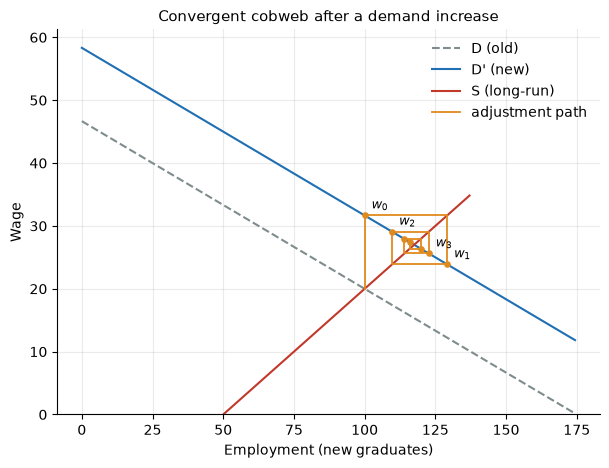

In [3]:
def cobweb_plot(ax, p, a_new, w, E, n=6, title=None):
    Eg = np.linspace(0, max(E.max(), p.E0) * 1.35, 200)
    ax.plot(Eg, p.a - p.b * Eg, color=GREY, ls="--", label="D (old)")
    ax.plot(Eg, a_new - p.b * Eg, color=BLUE, label="D' (new)")
    wg = np.linspace(0, w.max() * 1.1, 200)
    ax.plot(p.c + p.d * wg, wg, color=RED, label="S (long-run)")
    # path: (E_t, w_t) -> horizontal to supply at w_t gives E_{t+1} -> vertical to demand
    xs, ys = [E[0]], [p.w0]
    for i in range(n):
        xs += [E[i], E[i + 1]]; ys += [w[i], w[i]]
        xs += [E[i + 1]]; ys += [w[i + 1]]
    ax.plot(xs[1:], ys[1:], color=ORANGE, lw=1.3, label="adjustment path")
    ax.plot([p.E0, p.E0], [p.w0, w[0]], color=ORANGE, lw=1.3)
    ax.scatter(E[:n+1], w[:n+1], color=ORANGE, zorder=3, s=14)
    for i in range(min(n, 3) + 1):
        ax.annotate(f"$w_{i}$", (E[i], w[i]), textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax.set_xlabel("Employment (new graduates)"); ax.set_ylabel("Wage")
    ax.set_ylim(0, None); ax.set_title(title); ax.legend()

fig, ax = plt.subplots(figsize=(7, 5))
cobweb_plot(ax, p, a_new, w, E, title="Convergent cobweb after a demand increase")
plt.show()

## 4. Time series and the three regimes

Changing the supply elasticity relative to demand moves $bd=\varepsilon_S/|\delta|$ across 1.

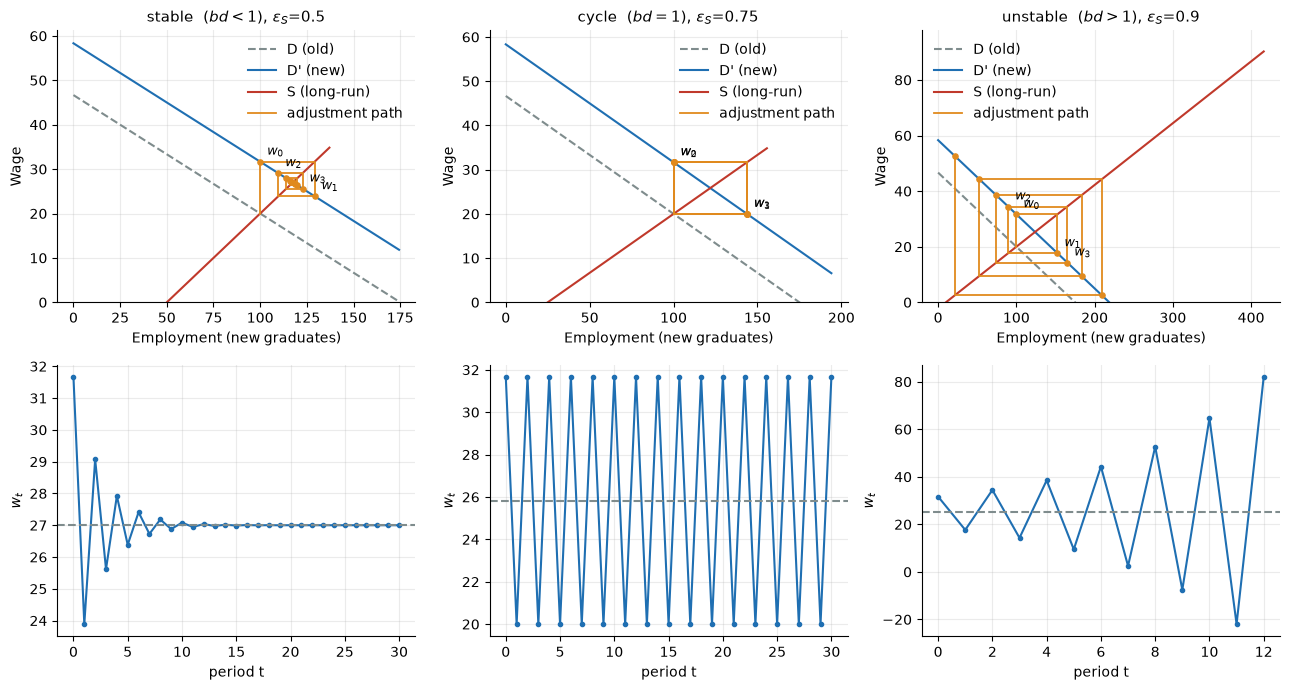

In [4]:
cases = {"stable  ($bd<1$)": 0.5, "cycle  ($bd=1$)": 0.75, "unstable  ($bd>1$)": 0.9}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, (name, eS) in enumerate(cases.items()):
    wj, Ej, pj, aj = simulate(T=30 if j < 2 else 12, eps_S=eS)
    cobweb_plot(axes[0, j], pj, aj, wj, Ej, n=8, title=name + f", $\\varepsilon_S$={eS}")
    axes[1, j].plot(wj, "o-", color=BLUE, ms=3)
    ws = (aj - pj.b * pj.c) / (1 + pj.b * pj.d)
    axes[1, j].axhline(ws, color=GREY, ls="--"); axes[1, j].set_xlabel("period t"); axes[1, j].set_ylabel("$w_t$")
fig.tight_layout(); plt.show()

## 5. Individual students

The aggregate rule $E_{t+1}=c+d\,w_t$ should come from individual decisions. Let a group of students have heterogeneous cost-of-studying thresholds $k_i \sim U(0, 40)$; student $i$ enrols in period $t+1$ if the wage seen in period $t$ exceeds $k_i$:

$$e_{i,t+1} = \mathbf 1\{w_t > k_i\}.$$

Each simulated student stands for $100/N$ graduates, and 50 "committed" graduates enrol regardless of the wage (this gives the intercept $c=50$). The slope $d$ is then $100/40 = 2.5$ — exactly as above — because the share enrolling is the CDF of $k_i$.

max |micro - aggregate| wage gap: 0.102


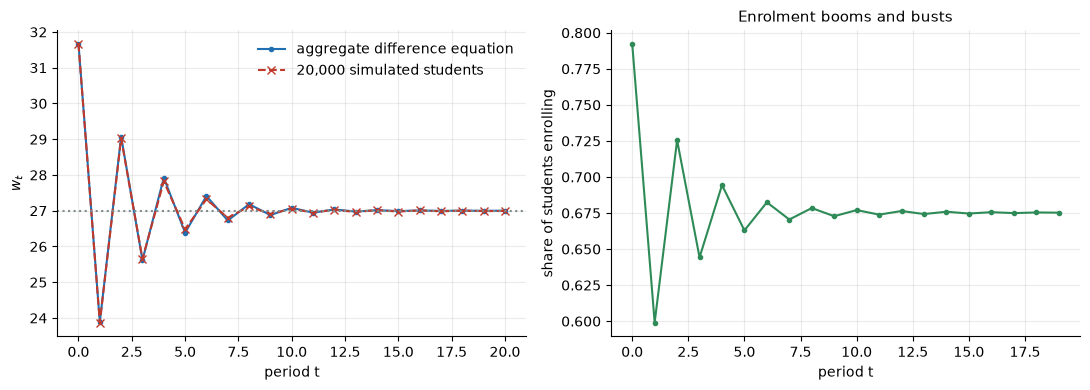

In [5]:
rng = np.random.default_rng(cobweb.seed)
N = cobweb.N
k = rng.uniform(0, 40, N)           # individual thresholds
weight = 100 / N
committed = 50.0

def simulate_students(T=cobweb.T):
    wv = np.empty(T + 1); Ev = np.empty(T + 1); enrol_share = np.empty(T + 1)
    Ev[0] = p.E0; wv[0] = a_new - p.b * Ev[0]
    for t in range(T):
        enrol = wv[t] > k                       # each student's decision
        enrol_share[t] = enrol.mean()
        Ev[t + 1] = committed + weight * enrol.sum()
        wv[t + 1] = a_new - p.b * Ev[t + 1]
    return wv, Ev, enrol_share

wv, Ev, share = simulate_students()
print("max |micro - aggregate| wage gap:", np.abs(wv - w).max().round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(w, "o-", color=BLUE, ms=3, label="aggregate difference equation")
ax[0].plot(wv, "x--", color=RED, label=f"{N:,} simulated students")
ax[0].axhline(w_star, color=GREY, ls=":"); ax[0].set_xlabel("period t"); ax[0].set_ylabel("$w_t$"); ax[0].legend()
ax[1].plot(share[:-1], "o-", color=GREEN, ms=3)
ax[1].set_xlabel("period t"); ax[1].set_ylabel("share of students enrolling"); ax[1].set_title("Enrolment booms and busts")
fig.tight_layout(); plt.show()

## 6. Beyond myopia: adaptive and rational students

**Adaptive expectations.** Students form the expected wage $w^e_t = w^e_{t-1} + \lambda\,(w_{t-1}-w^e_{t-1})$ and enrol according to $E_{t+1}=c+d\,w^e_t$. With $\lambda=1$ we recover the cobweb; smaller $\lambda$ averages over history and damps the cycle (but can add slower oscillations).

**Informed students.** A share $\theta$ of students correctly forecasts the long-run wage $w^*$ (they "buy the information", as Borjas notes); the rest are myopic: $w^e_t = \theta w^* + (1-\theta) w_t$. Then the effective multiplier is $-(1-\theta)bd$, so with $\theta > 1-1/(bd)$ even an unstable cobweb **unravels**.

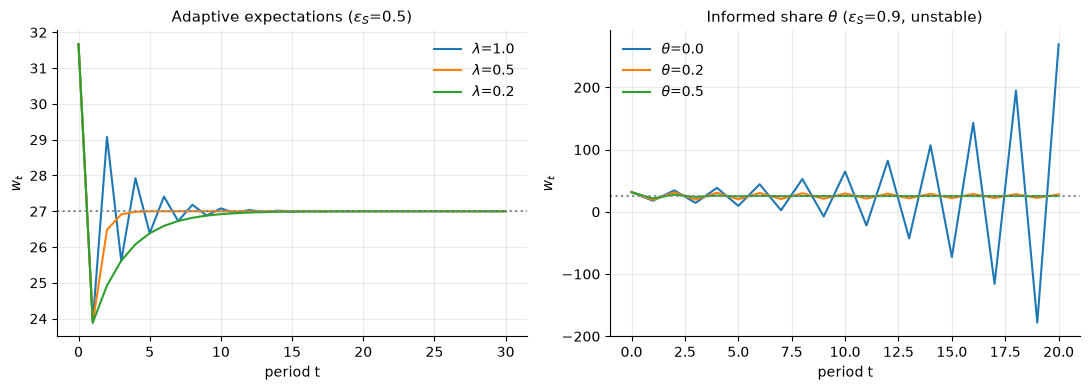

In [6]:
def simulate_expect(T=30, lam=1.0, theta=0.0, eps_S=None):
    pj = linear_market(eps_S=eps_S); aj = pj.a * (1 + cobweb.shock)
    ws = (aj - pj.b * pj.c) / (1 + pj.b * pj.d)
    wv = np.empty(T + 1); Ev = np.empty(T + 1)
    Ev[0] = pj.E0; wv[0] = aj - pj.b * Ev[0]
    we = wv[0]                                    # expectation of the wage
    for t in range(T):
        we = we + lam * (wv[t] - we)              # adaptive update
        fc = theta * ws + (1 - theta) * we        # informed share knows w*
        Ev[t + 1] = pj.c + pj.d * fc
        wv[t + 1] = aj - pj.b * Ev[t + 1]
    return wv, ws

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for lam in (1.0, 0.5, 0.2):
    wv_, ws_ = simulate_expect(lam=lam, eps_S=0.5); axes[0].plot(wv_, label=f"$\\lambda$={lam}")
axes[0].axhline(ws_, color=GREY, ls=":"); axes[0].set_title("Adaptive expectations ($\\varepsilon_S$=0.5)"); axes[0].legend()
for th in (0.0, 0.2, 0.5):
    wv_, ws_ = simulate_expect(theta=th, T=20, eps_S=0.9); axes[1].plot(wv_, label=f"$\\theta$={th}")
axes[1].axhline(ws_, color=GREY, ls=":"); axes[1].set_title("Informed share $\\theta$ ($\\varepsilon_S$=0.9, unstable)"); axes[1].legend()
for a_ in axes: a_.set_xlabel("period t"); a_.set_ylabel("$w_t$")
fig.tight_layout(); plt.show()

## Exercises

1. Show that at $bd=1$ the wage cycles with period 2. What is the amplitude?
2. Replace $E_{t+1}=c+d\,w_t$ by a two-year training lag, $E_{t+2}=c+d\,w_t$. What is the new characteristic equation and cycle length?
3. Let the demand shock be temporary (a bump for 3 periods). Does the cobweb produce a *larger* total swing than the shock itself?
4. For what $\theta$ is the cobweb stable when $\varepsilon_S=0.9$, $\delta=-0.75$? Check numerically.